In [1]:
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = {
    "Order_ID": range(1001, 1021),

    "Product": [
        "Laptop", "Mobile", "Tablet", "Laptop",
        "Mobile", "Headphones", "Tablet", "Laptop",
        "Mobile", "Headphones", "Laptop", "Tablet",
        "Mobile", "Laptop", "Headphones", "Tablet",
        "Mobile", "Laptop", "Tablet", "Headphones"
    ],

    "City": [
        "Delhi", "Mumbai", "Jaipur", "Delhi",
        "Mumbai", "Jaipur", "Delhi", "Mumbai",
        "Delhi", "Jaipur", "Delhi", "Mumbai",
        "Mumbai", "Delhi", "Jaipur", "Delhi",
        "Mumbai", "Delhi", "Jaipur", "Mumbai"
    ],

    "Sales": [
        50000, 20000, 15000, 45000,
        25000, 3000, 18000, 55000,
        22000, 4000, 48000, 17000,
        21000, 52000, 3500, 16000,
        23000, 51000, 19000, 4500
    ],

    "Quantity": [
        1, 2, 1, 1, 2, 3, 1, 1, 2, 2,
        1, 1, 2, 1, 2, 1, 2, 1, 1, 1
    ],

    "Month": [
        "January", "January", "January",
        "February", "February", "February",
        "March", "March", "March",
        "April", "April", "April",
        "May", "May", "May",
        "June", "June", "June",
        "July", "July"
    ]
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
df

Dataset created successfully!


,Order_ID,Product,City,Sales,Quantity,Month
0,1001,Laptop,Delhi,50000,1,January
1,1002,Mobile,Mumbai,20000,2,January
2,1003,Tablet,Jaipur,15000,1,January
3,1004,Laptop,Delhi,45000,1,February
4,1005,Mobile,Mumbai,25000,2,February
5,1006,Headphones,Jaipur,3000,3,February
6,1007,Tablet,Delhi,18000,1,March
7,1008,Laptop,Mumbai,55000,1,March
8,1009,Mobile,Delhi,22000,2,March
9,1010,Headphones,Jaipur,4000,2,April


In [3]:
print("First 5 rows:")
display(df.head())

print("Dataset shape:")
print(df.shape)

print("Dataset information:")
df.info()

print("Statistical summary:")
display(df.describe())

print("Total sales:")
print(df["Sales"].sum())

print("Total units sold:")
print(df["Quantity"].sum())

First 5 rows:


,Order_ID,Product,City,Sales,Quantity,Month
0,1001,Laptop,Delhi,50000,1,January
1,1002,Mobile,Mumbai,20000,2,January
2,1003,Tablet,Jaipur,15000,1,January
3,1004,Laptop,Delhi,45000,1,February
4,1005,Mobile,Mumbai,25000,2,February


Dataset shape:
(20, 6)
Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Order_ID  20 non-null     int64 
 1   Product   20 non-null     object
 2   City      20 non-null     object
 3   Sales     20 non-null     int64 
 4   Quantity  20 non-null     int64 
 5   Month     20 non-null     object
dtypes: int64(3), object(3)
memory usage: 1.1+ KB
Statistical summary:


,Order_ID,Sales,Quantity
count,20.00000,20.000000,20.000000
mean,1010.50000,25600.000000,1.450000
std,5.91608,17834.472828,0.604805
min,1001.00000,3000.000000,1.000000
25%,1005.75000,15750.000000,1.000000
50%,1010.50000,20500.000000,1.000000
75%,1015.25000,45750.000000,2.000000
max,1020.00000,55000.000000,3.000000


Total sales:
512000
Total units sold:
29


In [4]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:")
print(df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing numerical values if any exist
df["Sales"] = df["Sales"].fillna(df["Sales"].mean())

# Fill missing text values if any exist
df["Product"] = df["Product"].fillna("Unknown")
df["City"] = df["City"].fillna("Unknown")
df["Month"] = df["Month"].fillna("Unknown")

print("Data cleaning completed!")

Missing values:
Order_ID    0
Product     0
City        0
Sales       0
Quantity    0
Month       0
dtype: int64
Duplicate rows:
0
Data cleaning completed!


In [5]:
total_revenue = df["Sales"].sum()
total_units = df["Quantity"].sum()
average_sales = df["Sales"].mean()

print("RETAIL SALES SUMMARY")
print("--------------------")

print("Total Revenue: ₹", total_revenue)
print("Total Units Sold:", total_units)
print("Average Transaction: ₹", average_sales)

RETAIL SALES SUMMARY
--------------------
Total Revenue: ₹ 512000
Total Units Sold: 29
Average Transaction: ₹ 25600.0


In [6]:
product_analysis = df.groupby("Product").agg(
    Total_Revenue=("Sales", "sum"),
    Total_Quantity=("Quantity", "sum")
)

print("Product Performance:")
display(product_analysis)

# Product with highest revenue
best_product = product_analysis["Total_Revenue"].idxmax()

print("Highest Revenue Product:", best_product)

# Product with highest quantity sold
popular_product = product_analysis["Total_Quantity"].idxmax()

print("Most Sold Product:", popular_product)

Product Performance:


,Total_Revenue,Total_Quantity
Product,,
Headphones,15000,8
Laptop,301000,6
Mobile,111000,10
Tablet,85000,5


Highest Revenue Product: Laptop
Most Sold Product: Mobile


In [7]:
city_sales = df.groupby("City")["Sales"].sum()

print("City-wise Revenue:")
display(city_sales)

best_city = city_sales.idxmax()

print("Highest Revenue City:", best_city)

City-wise Revenue:


,Sales
City,
Delhi,302000
Jaipur,44500
Mumbai,165500


Highest Revenue City: Delhi


In [8]:
monthly_sales = df.groupby("Month")["Sales"].sum()

print("Monthly Revenue:")
display(monthly_sales)

best_month = monthly_sales.idxmax()

print("Best Performing Month:", best_month)

Monthly Revenue:


,Sales
Month,
April,69000
February,73000
January,85000
July,23500
June,90000
March,95000
May,76500


Best Performing Month: March


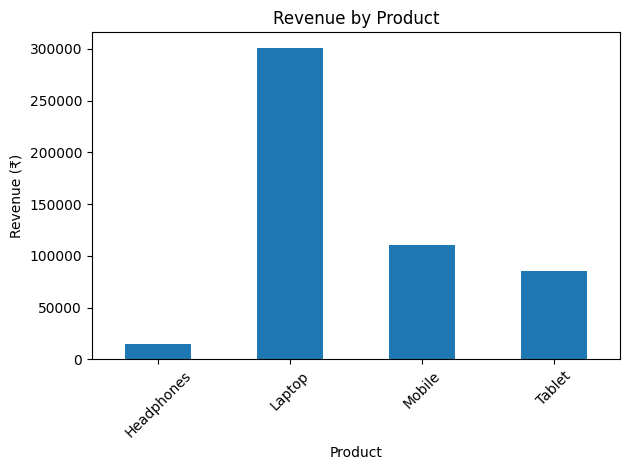

In [9]:
product_sales = df.groupby("Product")["Sales"].sum()

product_sales.plot(
    kind="bar",
    title="Revenue by Product",
    xlabel="Product",
    ylabel="Revenue (₹)"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

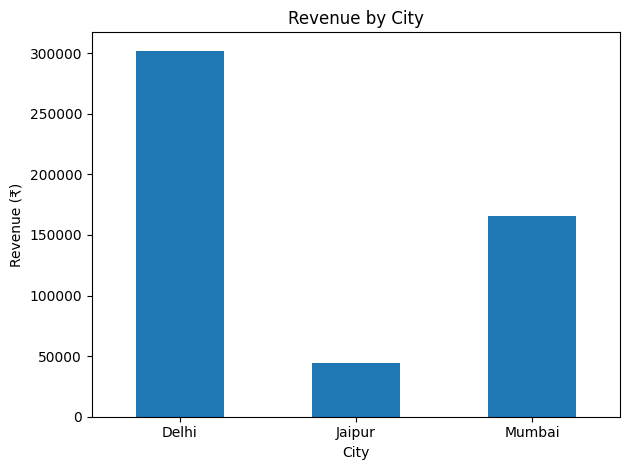

In [10]:
city_sales.plot(
    kind="bar",
    title="Revenue by City",
    xlabel="City",
    ylabel="Revenue (₹)"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

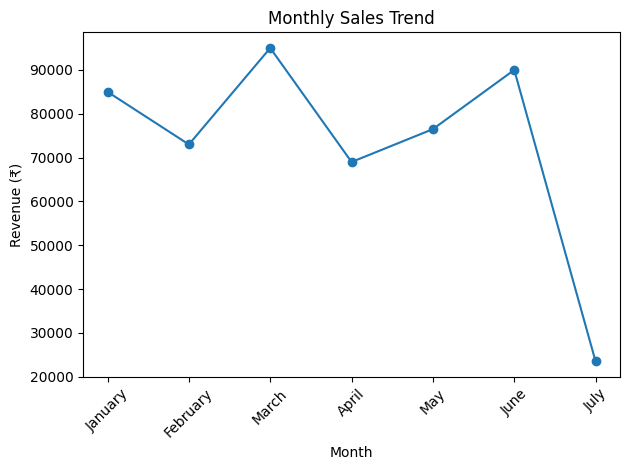

In [11]:
month_order = [
    "January", "February", "March",
    "April", "May", "June", "July"
]

monthly_sales = df.groupby("Month")["Sales"].sum()
monthly_sales = monthly_sales.reindex(month_order)

monthly_sales.plot(
    kind="line",
    marker="o",
    title="Monthly Sales Trend",
    xlabel="Month",
    ylabel="Revenue (₹)"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

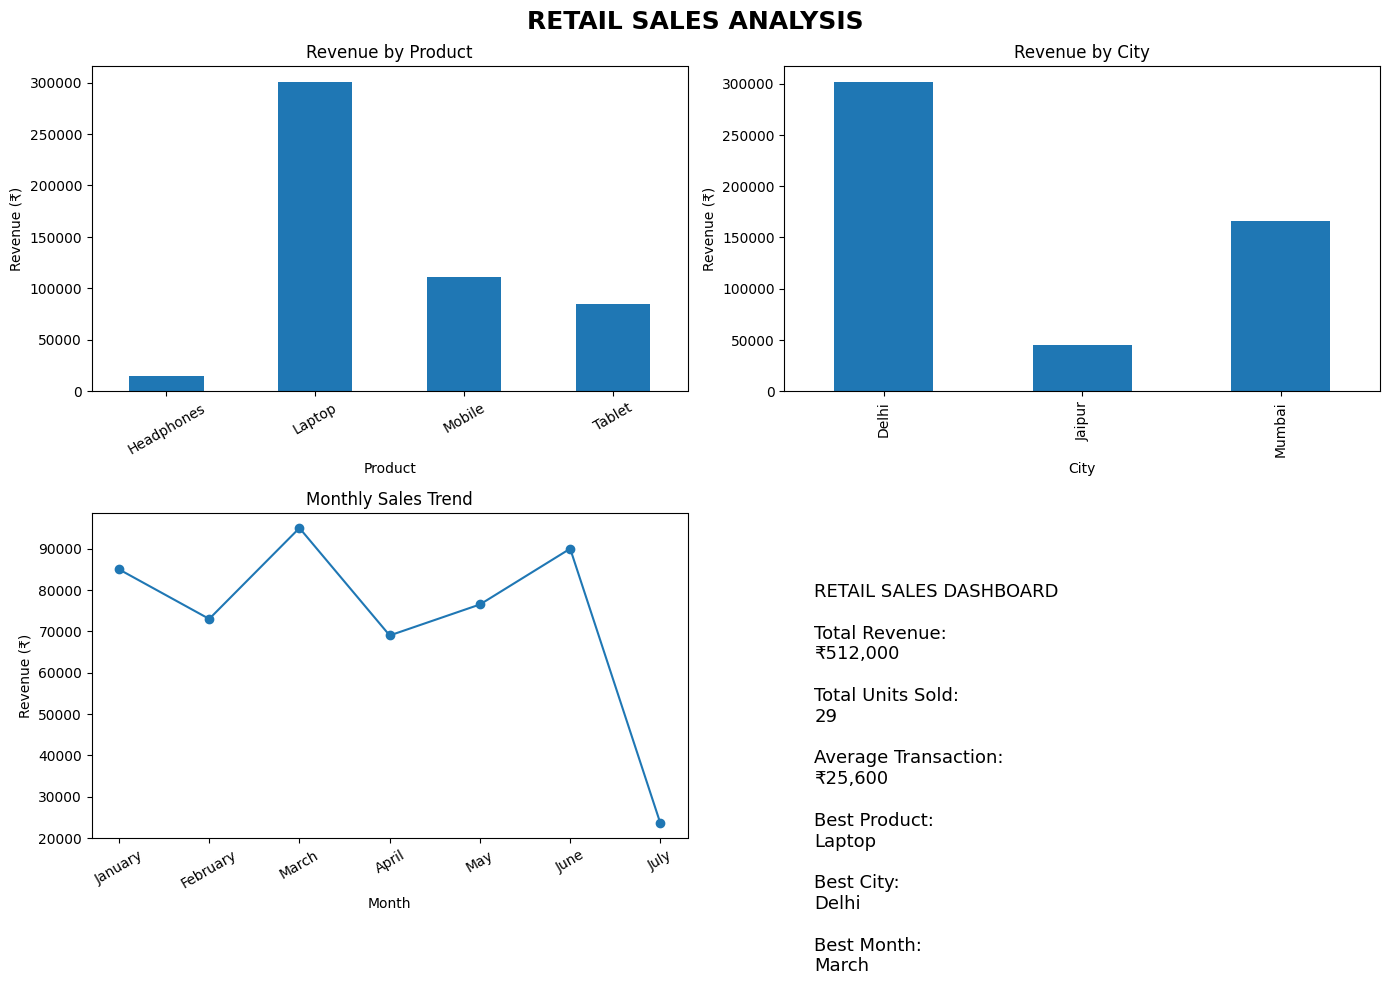

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Product chart
product_sales.plot(
    kind="bar",
    ax=axes[0, 0],
    title="Revenue by Product"
)
axes[0, 0].set_ylabel("Revenue (₹)")
axes[0, 0].tick_params(axis="x", rotation=30)

# City chart
city_sales.plot(
    kind="bar",
    ax=axes[0, 1],
    title="Revenue by City"
)
axes[0, 1].set_ylabel("Revenue (₹)")

# Monthly chart
monthly_sales.plot(
    kind="line",
    marker="o",
    ax=axes[1, 0],
    title="Monthly Sales Trend"
)
axes[1, 0].set_ylabel("Revenue (₹)")
axes[1, 0].tick_params(axis="x", rotation=30)

# Summary
axes[1, 1].axis("off")

summary = f"""
RETAIL SALES DASHBOARD

Total Revenue:
₹{total_revenue:,.0f}

Total Units Sold:
{total_units}

Average Transaction:
₹{average_sales:,.0f}

Best Product:
{best_product}

Best City:
{best_city}

Best Month:
{best_month}
"""

axes[1, 1].text(
    0.05, 0.85,
    summary,
    fontsize=13,
    verticalalignment="top"
)

plt.suptitle(
    "RETAIL SALES ANALYSIS",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "retail_sales_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
df.to_csv("sales_data.csv", index=False)

print("CSV file saved successfully!")

CSV file saved successfully!


In [14]:
from google.colab import files

files.download("sales_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
files.download("retail_sales_dashboard.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>